In [ ]:
            ############# Binary Classification Deep Neural Network #############
        ####################Predicting High Versus Low pH ######################

In [34]:
########## 1. Installing and Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# conda install conda-forge::seaborn
import statsmodels.api as sm
# conda install conda-forge::statsmodels

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

In [35]:
################ 2. Loading the dataset
data = pd.read_csv('E:/VData/SData/Wells4.csv')

In [36]:
# Set random seed for reproducibility purposes
np.random.seed(42)
tf.random.set_seed(42)

In [37]:
data.head()

,x_coord,y_coord,Depth,pH,SO4,NO3,T
0,17.74,15.57,259.0,7.00,39.0,9.0,27.0
1,17.48,15.82,220.0,6.60,17.0,12.0,34.7
2,17.48,15.83,220.0,6.00,925.0,5.0,27.0
3,17.39,15.37,286.0,7.00,3300.0,1.0,29.0
4,17.35,13.80,47.0,7.45,13.0,0.2,26.5


In [38]:
## a. Defining the threshold pH: < 7 is acidic (1), > 7 is basic (0)
NEUTRAL = 7 # The threshold
data['acidic_well'] = (data['pH'] < NEUTRAL).astype(int)

In [39]:
## b. Checking the class distribution
print(data['acidic_well'].value_counts())

acidic_well
0    710
1    601
Name: count, dtype: int64


In [40]:
##### 3. Features and Binary Target preparation

In [41]:
# a. The binary target
y = data['acidic_well']

In [42]:
# b. The features
X = data[['x_coord', 'y_coord', 'T', 'Depth']]

In [43]:
# c. Standardizing / Scaling the input features
scaler = StandardScaler() # # Initializing the scaler 
scaler.fit(X) # Fitting the scaler on X
# Scaling X
X = scaler.transform(X)

In [44]:
## d. Splitting the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

In [45]:
#  Printing the feature training and testing sizes
print(f'The training data size is: {X_train.shape}')
print(f'The testing size is: {X_test.shape}')

The training data size is: (917, 4)
The testing size is: (394, 4)


In [46]:
########### 4. Building Classification Neural Network Architecture
# Main changes for classification:
#•	Output Layer Activation: Changed from linear to sigmoid (outputs probabilities between 0 and 1).
#•	Loss Function: Changed from mse to binary_crossentropy.
#•	Metrics: Track accuracy and AUC.

In [48]:
def build_classification_dnn(input_dim):
    model = Sequential([
        # Input Layer + Hidden Layer 1
        Dense(64, activation = 'relu', input_shape = (input_dim,)),
        BatchNormalization(),
        Dropout(0.2),
        
        # Hidden Layer 2
        Dense(32, activation = 'relu'),
        BatchNormalization(),
        Dropout(0.2),
        
        # Hidden Layer 3
        Dense(16, activation = 'relu'),
        
        # Output Layer (Sigmoid for probability output)
        Dense(1, activation = 'sigmoid')
    ])
    
    model.compile(
        optimizer = tf.keras.optimizers.SGD(learning_rate = 0.005),
        loss = 'binary_crossentropy',
        metrics = ['accuracy', tf.keras.metrics.AUC(name = 'auc')]
    )
    return model

model = build_classification_dnn(X_train.shape[1])
model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                      │ (None, 64)                  │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 64)                  │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 32)                  │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,329 (13.00 KB)

 Trainable params: 3,137 (12.25 KB)

 Non-trainable params: 192 (768.00 B)

In [49]:
############## 5. Training the Classification Model

In [50]:
# Implementing Early Stopping on the training dataset to prevent overfitting
early_stop = EarlyStopping(
    monitor = 'val_loss', 
    patience = 15, 
    restore_best_weights = True
)

history = model.fit(
    X_train, y_train,
    validation_split = 0.3,
    epochs = 150,
    batch_size = 16,
    callbacks = [early_stop],
    verbose = 1
)


Epoch 1/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.5491 - auc: 0.5101 - loss: 0.9293 - val_accuracy: 0.6159 - val_auc: 0.5980 - val_loss: 0.6763
Epoch 2/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5772 - auc: 0.5826 - loss: 0.7634 - val_accuracy: 0.6268 - val_auc: 0.6614 - val_loss: 0.6641
Epoch 3/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5866 - auc: 0.6180 - loss: 0.7163 - val_accuracy: 0.6630 - val_auc: 0.6957 - val_loss: 0.6546
Epoch 4/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6334 - auc: 0.6591 - loss: 0.6756 - val_accuracy: 0.6486 - val_auc: 0.7016 - val_loss: 0.6466
Epoch 5/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6131 - auc: 0.6568 - loss: 0.6820 - val_accuracy: 0.6558 - val_auc: 0.6993 - val_loss: 0.6409
Epoch 6/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6115 - auc: 0.6633 - loss: 0.6626 - val_accuracy: 0.6667 - val_auc: 0.6982 - val_loss: 0.6356
Epoch 7/150
41/41 ━━━━━━━━━━━━━━━━━━━━ 1

In [29]:
################ 6. Model Evaluation  and Visualization #########################

In [51]:
# a. Predict probabilities and convert to binary classes (0 or 1)
y_pred_probs = model.predict(X_test).flatten()
y_pred = (y_pred_probs >= 0.5).astype(int)

# b. Classification Metrics
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Acidic Well (pH < 7)', 'Basic Well (pH > 7)']))

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step

--- Classification Report ---
                      precision    recall  f1-score   support

Acidic Well (pH < 7)       0.73      0.76      0.74       209
 Basic Well (pH > 7)       0.71      0.68      0.70       185

            accuracy                           0.72       394
           macro avg       0.72      0.72      0.72       394
        weighted avg       0.72      0.72      0.72       394



In [31]:
################ Visualization #############

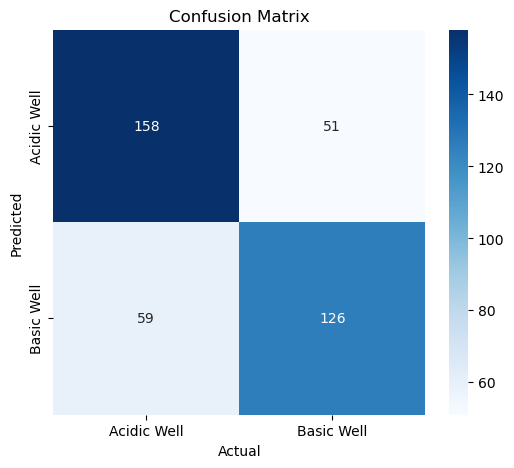

In [54]:
### a. Confusion Matrix Plot
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize = (6, 5))
sns.heatmap(cm, annot = True, fmt ='d', cmap ='Blues', 
            xticklabels = ['Acidic Well', 'Basic Well'], 
            yticklabels = ['Acidic Well', 'Basic Well'])
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

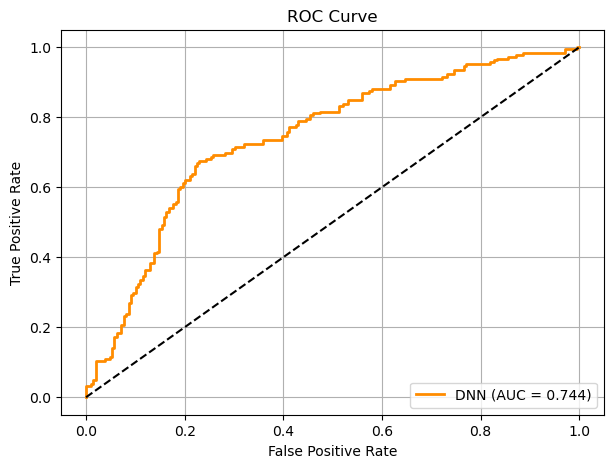

In [55]:
##### b. Receiver Operating Characteristics (ROC) Curve  
fpr, tpr, _ = roc_curve(y_test, y_pred_probs)
auc_val = roc_auc_score(y_test, y_pred_probs)

plt.figure(figsize = (7, 5))
plt.plot(fpr, tpr, label = f'DNN (AUC = {auc_val:.3f})', color = 'darkorange', lw = 2)
plt.plot([0, 1], [0, 1], 'k--', lw = 1.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc = 'lower right')
plt.grid(True)
plt.show()